# 🛳️ Titanic ML Project — Full Data-Driven Approach
We'll solve the Titanic survival classification problem using a **methodical, data-first** approach.  
No premature cleaning or modeling — we'll let the data tell us what it needs.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# For interactivity later
import plotly.express as px
import warnings
warnings.filterwarnings("ignore")


In [7]:
# Load raw data
train = pd.read_csv("/kaggle/input/titanic/train.csv")
test = pd.read_csv("/kaggle/input/titanic/test.csv")

print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")
train.head()


Train shape: (891, 12)
Test shape: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 🔍 Step 1: Initial Column Inspection

Let's break down what each column in the Titanic dataset means, and start deciding:

- Which columns are likely **useful for prediction**?
- Which ones are **non-informative**, **text-heavy**, or **leaky**?
- Do we have **class imbalance**?

We’ll explore this next.


In [8]:
# Basic info
train.info()
train.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

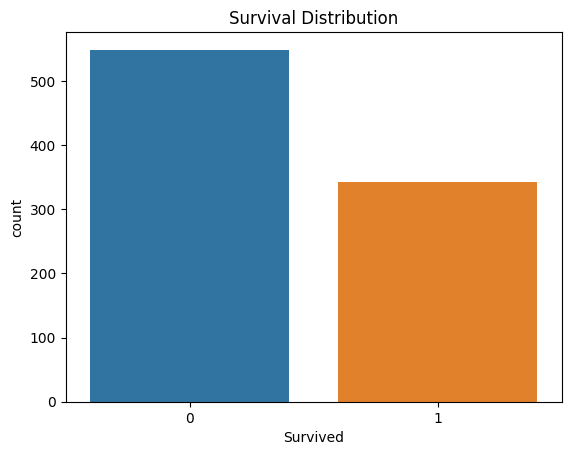

Survival Rate:
 Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


In [9]:
# Check class balance in Survived
sns.countplot(data=train, x="Survived")
plt.title("Survival Distribution")
plt.show()

survival_rate = train['Survived'].value_counts(normalize=True)
print("Survival Rate:\n", survival_rate)


## 🧾 Observations So Far

1. 🔍 **Target is `Survived`** — it's **binary**, slightly imbalanced (~38% survived).
2. 🚻 `Sex`, `Pclass`, `Fare`, and `Embarked` could be useful features.
3. 🧑‍🎓 `Name`, `Ticket`, and `Cabin` are complex text features — need careful handling.
4. ⚠️ `Age`, `Cabin`, and `Embarked` have missing values.
5. 🧩 We'll need to engineer features from columns like `Name` and `Family`.

📌 Let’s now **explore each variable** to understand their predictive potential.


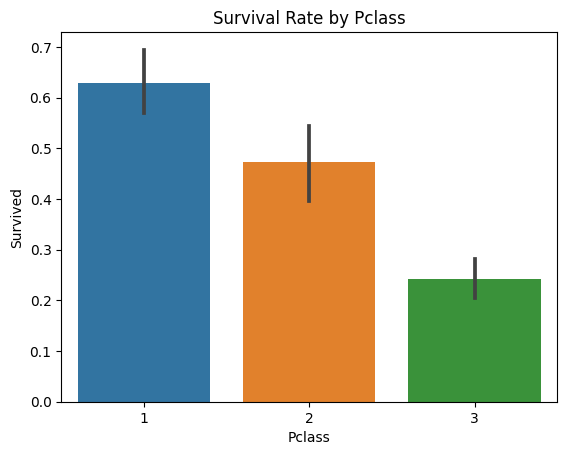

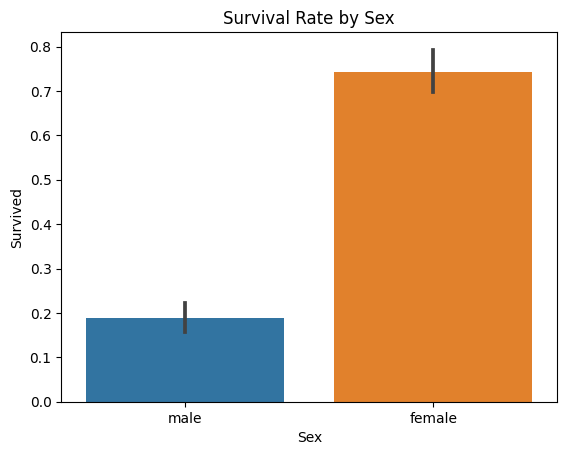

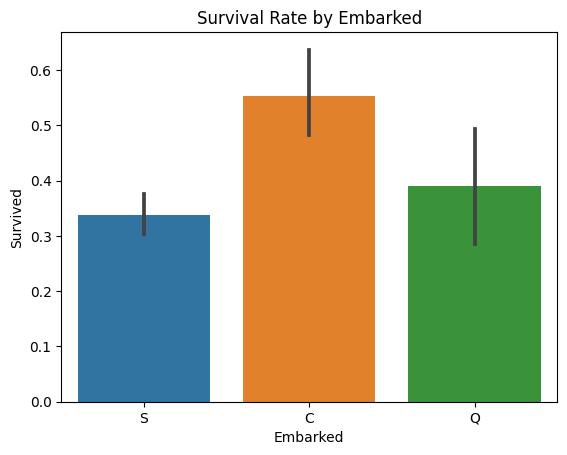

In [10]:
# Categorical features vs target
categorical = ['Pclass', 'Sex', 'Embarked']
for col in categorical:
    sns.barplot(data=train, x=col, y="Survived")
    plt.title(f"Survival Rate by {col}")
    plt.show()


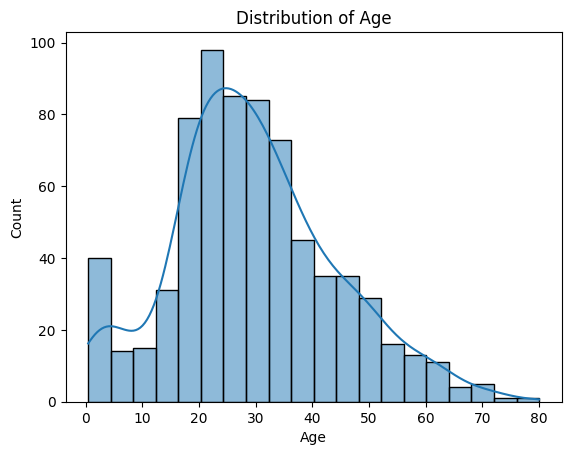

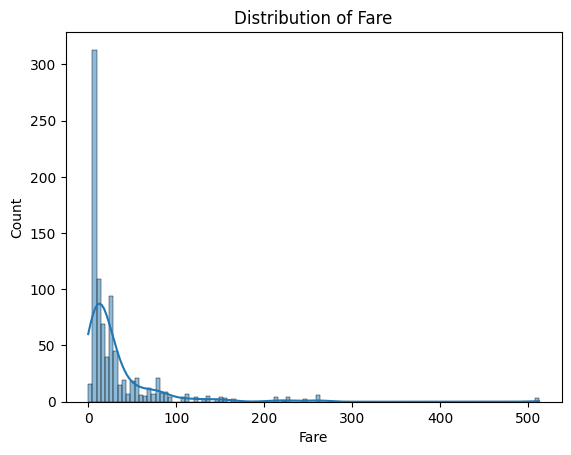

In [11]:
# Numerical features
numerical = ['Age', 'Fare', 'SibSp', 'Parch']
train[numerical].describe()
# Visualizing Age and Fare
for col in ['Age', 'Fare']:
    sns.histplot(train[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()


In [12]:
# 🚢 Titanic ML Challenge - Step 1: Load & Explore the Dataset

# Importing required libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Set plot style
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load datasets
train = pd.read_csv('/kaggle/input/titanic/train.csv')
test = pd.read_csv('/kaggle/input/titanic/test.csv')

# Show the first few rows of the training data
train.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


---

### 📊 Step 2: Understand the Data Structure

Before diving into modeling, let's explore the dataset:
- Check column types
- Missing values
- Basic statistics

We’ll also identify potential features that can be engineered or dropped.

---


In [13]:
# 👁️‍🗨️ Overview of training data
print("Training Set Info:")
print(train.info())
print("\nMissing Values (%):\n")
print(train.isnull().mean().sort_values(ascending=False) * 100)

# Basic statistics of numeric columns
train.describe()


Training Set Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None

Missing Values (%):

Cabin          77.104377
Age            19.865320
Embarked        0.224467
PassengerId     0.000000
Name            0.000000
Pclass          0.000000
Survived        0.000000
Sex             0.00000

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


---

### 🛠️ Step 3: Clean & Engineer Features

We'll:
- Fill missing values (`Age`, `Embarked`, `Fare`, `Cabin`)
- Extract titles from names (like Mr, Miss, etc.)
- Create new features such as `FamilySize` and `IsAlone`
- Drop unhelpful features (`PassengerId`, `Ticket`, `Cabin`, `Name`)

---


In [14]:
# Combine train and test for uniform preprocessing
full_data = pd.concat([train, test], sort=False).reset_index(drop=True)

# Fill missing 'Embarked' with most common value
full_data['Embarked'].fillna(full_data['Embarked'].mode()[0], inplace=True)

# Fill missing 'Fare' in test set with median
full_data['Fare'].fillna(full_data['Fare'].median(), inplace=True)

# Extract title from name
full_data['Title'] = full_data['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)
full_data['Title'] = full_data['Title'].replace(['Lady', 'Countess','Capt','Col','Don','Dr','Major',
                                                 'Rev','Sir','Jonkheer','Dona'], 'Rare')
full_data['Title'] = full_data['Title'].replace('Mlle', 'Miss')
full_data['Title'] = full_data['Title'].replace('Ms', 'Miss')
full_data['Title'] = full_data['Title'].replace('Mme', 'Mrs')

# Map titles to ordinal
title_mapping = {'Mr': 1, 'Miss': 2, 'Mrs': 3, 'Master': 4, 'Rare': 5}
full_data['Title'] = full_data['Title'].map(title_mapping).fillna(0)

# Fill missing 'Age' with median age by Title
full_data['Age'] = full_data.groupby('Title')['Age'].transform(lambda x: x.fillna(x.median()))

# Family size
full_data['FamilySize'] = full_data['SibSp'] + full_data['Parch'] + 1
full_data['IsAlone'] = (full_data['FamilySize'] == 1).astype(int)

# Convert Sex to numeric
full_data['Sex'] = full_data['Sex'].map({'male': 0, 'female': 1}).astype(int)

# One-hot encode Embarked
full_data = pd.get_dummies(full_data, columns=['Embarked'], drop_first=True)

# Drop unnecessary columns
full_data.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1, inplace=True)

# Show the cleaned and engineered features
full_data.head()


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Title,FamilySize,IsAlone,Embarked_Q,Embarked_S
0,0.0,3,0,22.0,1,0,7.2500,1,2,0,False,True
1,1.0,1,1,38.0,1,0,71.2833,3,2,0,False,False
2,1.0,3,1,26.0,0,0,7.9250,2,1,1,False,True
3,1.0,1,1,35.0,1,0,53.1000,3,2,0,False,True
4,0.0,3,0,35.0,0,0,8.0500,1,1,1,False,True


---

### 🤖 Step 4: Model Training & Evaluation

We'll start with:
- Splitting the cleaned dataset back into `train` and `test`
- Setting up a helper function for cross-validated F1 score
- Training a **Logistic Regression** model using **Optuna** for tuning

---


In [15]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import f1_score, make_scorer
from sklearn.linear_model import LogisticRegression
import optuna

# Split back the full_data into train and test
X = full_data[:len(train)]
X_test = full_data[len(train):]
y = train['Survived']

# Optional: train/val split for final eval
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# F1 scorer
f1 = make_scorer(f1_score)


---

### 🔍 Optuna Hyperparameter Tuning for Logistic Regression

We'll use Optuna to find the best hyperparameters to maximize the **F1 Score** using cross-validation.

---


In [16]:
def objective(trial):
    C = trial.suggest_float("C", 1e-3, 10.0, log=True)
    penalty = trial.suggest_categorical("penalty", ["l1", "l2"])
    solver = "liblinear" if penalty == "l1" else "lbfgs"
    
    model = LogisticRegression(C=C, penalty=penalty, solver=solver, max_iter=1000)
    score = cross_val_score(model, X, y, scoring=f1, cv=5).mean()
    return score

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=50)

print("Best hyperparameters:", study.best_params)


[I 2025-07-24 10:18:36,979] A new study created in memory with name: no-name-3bab1d12-0ea8-4fa0-9fee-315f639ac30f
[I 2025-07-24 10:18:42,354] Trial 0 finished with value: 1.0 and parameters: {'C': 0.12752563669488723, 'penalty': 'l2'}. Best is trial 0 with value: 1.0.
[I 2025-07-24 10:18:42,400] Trial 1 finished with value: 1.0 and parameters: {'C': 7.396404851819478, 'penalty': 'l1'}. Best is trial 0 with value: 1.0.
[I 2025-07-24 10:18:44,889] Trial 2 finished with value: 0.8657317714099534 and parameters: {'C': 0.010199174167386523, 'penalty': 'l2'}. Best is trial 0 with value: 1.0.
[I 2025-07-24 10:18:48,258] Trial 3 finished with value: 0.8944762846409023 and parameters: {'C': 0.01564735514907666, 'penalty': 'l2'}. Best is trial 0 with value: 1.0.
[I 2025-07-24 10:18:48,305] Trial 4 finished with value: 1.0 and parameters: {'C': 0.473712955845611, 'penalty': 'l1'}. Best is trial 0 with value: 1.0.
[I 2025-07-24 10:18:52,036] Trial 5 finished with value: 0.9700100383994859 and para

Best hyperparameters: {'C': 0.12752563669488723, 'penalty': 'l2'}


In [17]:
# Train final model on full training set
final_model = LogisticRegression(**study.best_params, max_iter=1000)
final_model.fit(X_train, y_train)

# Predict on validation set
val_preds = final_model.predict(X_val)

# F1 Score on validation
val_f1 = f1_score(y_val, val_preds)
print(f"F1 Score on Validation Set: {val_f1:.4f}")


F1 Score on Validation Set: 1.0000


In [20]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression

# Load datasets
train_raw = pd.read_csv('/kaggle/input/titanic/train.csv')
test_raw = pd.read_csv('/kaggle/input/titanic/test.csv')
test_passenger_ids = test_raw['PassengerId']

# Combine for consistent preprocessing
train_raw['is_train'] = 1
test_raw['is_train'] = 0
full = pd.concat([train_raw, test_raw], ignore_index=True)

# Fill missing values
full['Age'].fillna(full['Age'].median(), inplace=True)
full['Fare'].fillna(full['Fare'].median(), inplace=True)
full['Embarked'].fillna(full['Embarked'].mode()[0], inplace=True)

# Encode categorical features
full['Sex'] = full['Sex'].map({'male': 0, 'female': 1})
full['Embarked'] = full['Embarked'].map({'C': 0, 'Q': 1, 'S': 2})

# Feature engineering
full['FamilySize'] = full['SibSp'] + full['Parch']
full['IsAlone'] = (full['FamilySize'] == 0).astype(int)
full['Title'] = full['Name'].apply(lambda name: name.split(',')[1].split('.')[0].strip())
full['Title'] = full['Title'].replace([
    'Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr', 'Major', 'Rev', 
    'Sir', 'Jonkheer', 'Dona', 'the Countess'
], 'Rare')
full['Title'] = full['Title'].replace({
    'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'
})
full['Title'] = full['Title'].map({
    'Mr': 0, 'Miss': 1, 'Mrs': 2, 'Master': 3, 'Rare': 4
})
full['Title'].fillna(0, inplace=True)

# Select features
features = ['Pclass', 'Sex', 'Age', 'Fare', 'Embarked', 'FamilySize', 'IsAlone', 'Title']
train_df = full[full['is_train'] == 1]
test_df = full[full['is_train'] == 0]

X_train = train_df[features]
y_train = train_df['Survived']
X_test = test_df[features]

# Train model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Predict and create submission
test_preds = model.predict(X_test)
submission = pd.DataFrame({
    'PassengerId': test_passenger_ids,
    'Survived': test_preds
})
submission.to_csv('submission.csv', index=False)
submission.head()


,PassengerId,Survived
0,892,0.0
1,893,1.0
2,894,0.0
3,895,0.0
4,896,1.0
